# Salo & Tahvonen (2001) — Nash feedback equilibrium, $n$-player symmetric oligopoly

Symmetric players: $\delta_i=\delta$, $c_i=c$ — heterogeneous initial stocks $x_{i0}$.

Feedback law (same $\mu_1,\mu_2$ for all): $q_i = \mu_1 z + \mu_2 x_i$, with $z=\sum_{j\neq i}x_j$.

Reference: *Journal of Economic Dynamics & Control* 25 (2001) 671–702, Section 3 & Appendix A.

## 1 — Hyperparameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Model parameters (symmetric players) ---
n      = 3          # number of producers  (n >= 2)
c      = 0.5        # cost slope: unit cost = pbar - c*x_i
delta  = 0.05       # discount rate (must be > 0)
pbar   = 10.0       # choke price  p = pbar - sum_j q_j

# --- Heterogeneous initial stocks (one entry per player) ---
x0 = np.array([8.0, 5.0, 4.0])
assert len(x0) == n, "x0 must have n entries"

# --- Time discretization for the reward integral ---
# Convention: dt is fixed, every horizon is reasoned about in time steps (not physical time).
dt    = 0.1       # time step
STEPS = 2000     # number of time steps for the reward integral (t_max = STEPS*dt)

## 2 — Theoretical solution (Proposition 3, closed form)

Solves Eqs. (20)–(21) via the ellipse + cubic factorization of Appendix A:

$$\mu_1 = -\frac{\alpha_1}{\sqrt{1+s^2}},\qquad
\mu_2 = \frac{\alpha_2 s + \tfrac12\alpha_1(n-1)}{\sqrt{1+s^2}} - \tfrac12\delta$$

with $s = \frac{\alpha_0}{3}\big\{p_0 + 2p_1\cos[\tfrac13\arccos(p_2/p_1^3)]\big\}$ and $\gamma=\delta/c$.

Roots recovered from Appendix A: $r_1=\mu_1-\mu_2,\ r_2=(1-n)\mu_1-\mu_2$ (sorted so $r_1<r_2<0$).

In [2]:
def theoretical_solution(n, c, delta):
    """Closed-form Nash feedback equilibrium coefficients (Prop. 3).
    Returns dict with mu1, mu2, r1, r2, s."""
    gamma = delta / c                          # c' = delta/c

    a0 = 1.0 / np.sqrt((3*n + 1) * (n - 1))
    a1 = a0 * np.sqrt(delta * (2*c + delta))
    a2 = 0.5 * np.sqrt(delta * (2*c + delta))

    p0 = -1 + gamma + 3*n + gamma*n
    p1 = np.sqrt(16 + 4*gamma + gamma**2
                 + (24 + 16*gamma + 2*gamma**2) * n
                 + (6*gamma + gamma**2) * n**2)
    p2 = (44 + 30*gamma + 6*gamma**2 + gamma**3
          + (180 + 102*gamma + 30*gamma**2 + 3*gamma**3) * n
          + (108*gamma + 33*gamma**2 + 3*gamma**3) * n**2
          + (9*gamma**2 + gamma**3) * n**3)

    s = (a0 / 3.0) * (p0 + 2*p1 * np.cos((1/3) * np.arccos(p2 / p1**3)))

    mu1 = -a1 / np.sqrt(1 + s**2)
    mu2 = (a2*s + 0.5*a1*(n - 1)) / np.sqrt(1 + s**2) - 0.5*delta

    # characteristic roots (Appendix A), ordered r1 < r2 < 0
    r1, r2 = sorted([mu1 - mu2, (1 - n)*mu1 - mu2])

    return dict(mu1=mu1, mu2=mu2, r1=r1, r2=r2, s=s)


sol = theoretical_solution(n, c, delta)
print(f"mu1 = {sol['mu1']:.6f}   (< 0 expected)")
print(f"mu2 = {sol['mu2']:.6f}   (> 0 expected)")
print(f"r1  = {sol['r1']:.6f}")
print(f"r2  = {sol['r2']:.6f}")

# sign / stability checks from the paper
assert sol['mu1'] < 0,                      "mu1 must be < 0"
assert sol['mu2'] > 0,                      "mu2 must be > 0"
assert sol['mu2'] + (n-1)*sol['mu1'] > 0,   "need mu2 + (n-1) mu1 > 0"
assert sol['r1'] < sol['r2'] < 0,           "roots must be real, negative, r1<r2"
print("\nAll sign / stability conditions satisfied.")

mu1 = -0.022356   (< 0 expected)
mu2 = 0.100439   (> 0 expected)
r1  = -0.122795
r2  = -0.055726

All sign / stability conditions satisfied.


In [3]:
# Validation against the paper's reported values
#   footnote 8 (n=20): mu1~=-0.004518, mu2~=0.102834
#   footnote 5 (n=2) : mu1~=-0.0297813, mu2~=0.0974679
for nn, ref in [(20, (-0.004518, 0.102834)), (2, (-0.0297813, 0.0974679))]:
    s = theoretical_solution(nn, 0.5, 0.05)
    print(f"n={nn:2d}: mu1={s['mu1']:.6f} (ref {ref[0]:+.6f}), "
          f"mu2={s['mu2']:.6f} (ref {ref[1]:+.6f})")

# defining equations (20)-(21) residuals
m1, m2, r1, r2 = sol['mu1'], sol['mu2'], sol['r1'], sol['r2']
eq20 = m1*(2 - n) - 2*m2 - r1 - r2
eq21 = (m2 + r1)*(m2 + r2) - m1**2*(1 - n)
print(f"\nEq.(20) residual = {eq20:.2e}")
print(f"Eq.(21) residual = {eq21:.2e}")

n=20: mu1=-0.004518 (ref -0.004518), mu2=0.102834 (ref +0.102834)
n= 2: mu1=-0.029781 (ref -0.029781), mu2=0.097468 (ref +0.097468)

Eq.(20) residual = -6.94e-18
Eq.(21) residual = 2.17e-19


## 3 — Discounted reward of each player from a fixed initial stock

Roll the feedback law forward on a grid of step $dt$ and accumulate the discounted profit flux

$$J_i = \int_0^\infty \big[p - (\bar p - c\,x_i)\big]\,q_i\; e^{-\delta t}\,dt,
\qquad p = \bar p - \sum_j q_j,\quad q_i = \max(\mu_1 z + \mu_2 x_i,\,0).$$

State update: $x_i \leftarrow \max(x_i - q_i\,dt,\,0)$ (economic depletion, $q_i\ge 0$ regime).

In [4]:
def discounted_rewards(n, c, delta, pbar, x0, dt, steps, sol=None, return_paths=False):
    """Forward-simulate the symmetric feedback equilibrium and return each
    player's discounted reward J_i. Optionally return the (t, x, q, p) paths."""
    if sol is None:
        sol = theoretical_solution(n, c, delta)
    mu1, mu2 = sol['mu1'], sol['mu2']

    x = np.array(x0, dtype=float)
    J = np.zeros(n)

    if return_paths:
        X = np.empty((steps + 1, n)); Q = np.empty((steps, n)); P = np.empty(steps)
        X[0] = x

    for k in range(steps):
        t = k * dt
        z = x.sum() - x                        # z_i = sum_{j!=i} x_j
        q = np.maximum(mu1*z + mu2*x, 0.0)     # feedback supply, q_i >= 0
        p = pbar - q.sum()                     # market price
        cost = pbar - c*x                      # unit extraction cost
        flux = (p - cost) * q                  # instantaneous profit of each i
        J += np.exp(-delta*t) * flux * dt      # discounted, left-Riemann sum
        x = np.maximum(x - q*dt, 0.0)          # depletion
        if return_paths:
            Q[k] = q; P[k] = p; X[k + 1] = x

    if return_paths:
        tgrid = np.arange(steps + 1) * dt
        return J, tgrid, X, Q, P
    return J


J = discounted_rewards(n, c, delta, pbar, x0, dt, STEPS, sol=sol)
for i in range(n):
    print(f"Player {i}:  x0 = {x0[i]:5.2f}   J_i = {J[i]:.4f}")

Player 0:  x0 =  8.00   J_i = 8.8600
Player 1:  x0 =  5.00   J_i = 2.6600
Player 2:  x0 =  4.00   J_i = 1.4323


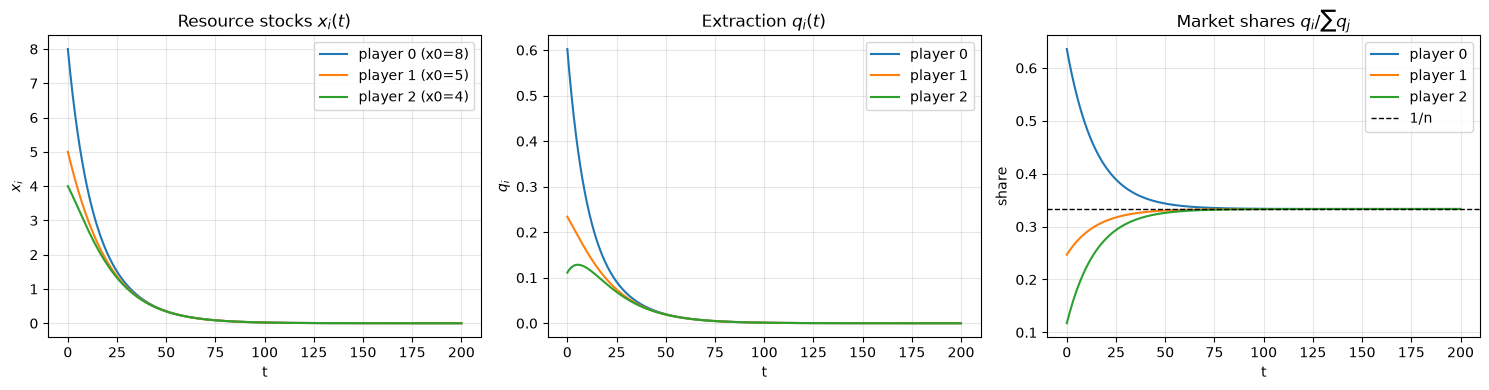

Market shares converge to 1/n = 0.3333 => turnpike (Prop. 4).


In [5]:
# Visualize stock and extraction paths + reward accumulation
J, tg, X, Q, P = discounted_rewards(n, c, delta, pbar, x0, dt, STEPS,
                                    sol=sol, return_paths=True)
tq = tg[:-1]

ZOOM_STEPS = 4000                       # zoom on the transient (first ZOOM_STEPS steps)
mask = np.arange(len(tg)) <= ZOOM_STEPS
mq   = np.arange(len(tq)) <= ZOOM_STEPS

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in range(n):
    ax[0].plot(tg[mask], X[mask, i], label=f'player {i} (x0={x0[i]:.0f})')
    ax[1].plot(tq[mq], Q[mq, i], label=f'player {i}')
ax[0].set(title='Resource stocks $x_i(t)$', xlabel='t', ylabel='$x_i$')
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set(title='Extraction $q_i(t)$', xlabel='t', ylabel='$q_i$')
ax[1].legend(); ax[1].grid(alpha=.3)

shares = Q / Q.sum(axis=1, keepdims=True)
for i in range(n):
    ax[2].plot(tq[mq], shares[mq, i], label=f'player {i}')
ax[2].axhline(1/n, ls='--', color='k', lw=1, label='1/n')
ax[2].set(title='Market shares $q_i/\\sum q_j$', xlabel='t', ylabel='share')
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Market shares converge to 1/n =", round(1/n, 4),
      "=> turnpike (Prop. 4).")

=== Nash gap of Salo & Tahvonen's theoretical equilibrium ===
player 0: J_policy=8.8654  J_best_response=8.5749  gap=-0.2905
player 1: J_policy=2.6623  J_best_response=2.4346  gap=-0.2277
player 2: J_policy=1.4338  J_best_response=1.4183  gap=-0.0155

nash_gap (mean over players) = -0.1779